 **A quick Introduction**

There are data scattered all around the internet.


The unique address where any of these resources are located is called the **URL (Uniform/Universal Resource Locator)**. The URLs are references to web resources.



**HTTP (HyperText Transfer Protocol)** is the base of data communication on the web. Whenever we interact with the web, we are trying to get data from it, i.e send http request.


HTTP Request (**GET request**) in plane english means getting data from the web.





# **Scrapping Reddit**

APIs(Application Programming Interface) are bunch of codes that allows two softwares to interact or communicate with each other.

For the purpose of collecting data, you can interact with standard websites using their APIs, e.g, reddits API, twitter API, etc.



**Accessing Reddits API**

In order to gain authentication for reddit API, you need to create a reddit developer app account by visiting https://www.reddit.com/prefs/apps. Then chose 'create app'(if you have not done so before', or 'create another app'(if you have created one before). This will open a form like the one below opens.

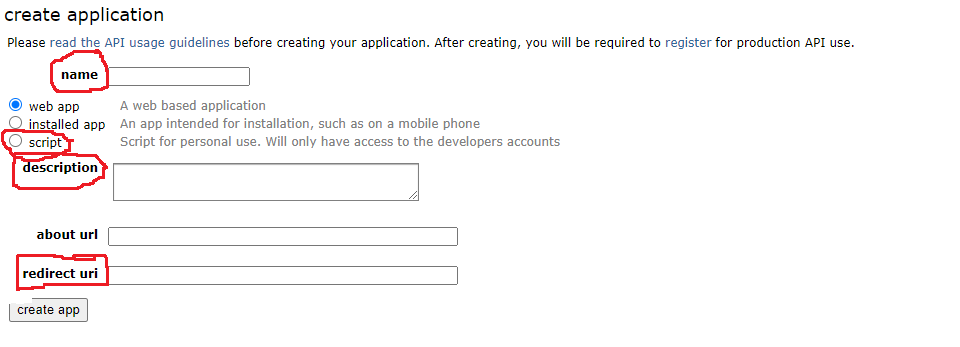

Fill out the form.

**Name** : This is the name you want the app to be called.

Click on **Script**.

**Description**. Give a short description of the app.

**redirect url**: Paste http://localhost:8080 there (don't follow the link, just copy and paste it), as described in PRAW documentation [here](https://praw.readthedocs.io/en/latest/getting_started/authentication.html#script-application).

Click on **create app**.

A new app with details like the one below will come up

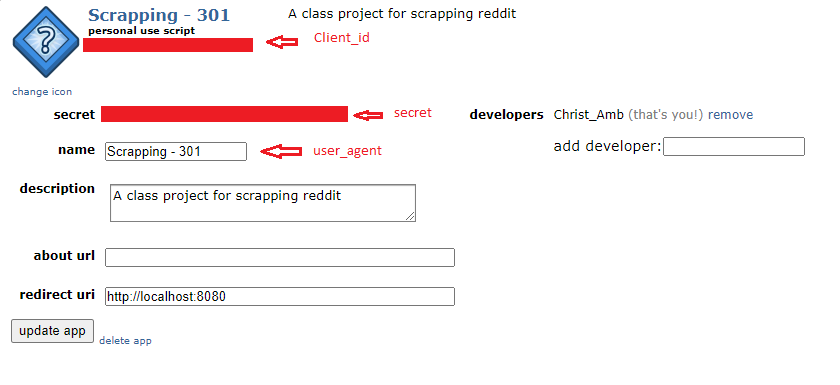

The details of this app will be used to authenticate your access to reddit using praw.

**PRAW** - Python Reddit API Wrapper. It is a python module that is used to collect data from reddit.

In [ ]:
#import libraries
!pip install praw
import requests
import pandas as pd
import praw

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 191.0/191.0 kB 4.5 MB/s eta 0:00:00


# **Scrapping Subreddit**

In [ ]:
# Passing your details
reddit = praw.Reddit(client_id='',
                     client_secret='',
                     user_agent='') # Put in your credentials


In [ ]:
# Accessing the subreddit data
sl_sub_data = reddit.subreddit('StudentLoans')    # Now we have our subreddit data in the name 'sl_sub_data'
# https://www.reddit.com/r/StudentLoans/

In [ ]:
sl_sub_data

Subreddit(display_name='StudentLoans')

In [ ]:
# get 10 hot posts from the StudentLoans subreddit
hot_sl_sub_data = sl_sub_data.hot(limit=10)     # Get the top 10 hot posts from the subreddit
for post in hot_sl_sub_data:                    # Use a for loop to iterate through the post
    print(post.title)                              # it will print out the objects id. We can get the title by calling .title
                                                # We can also get items such as the score, number of upvotes(ups), downvotes(downs), num_comments etc.

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.



Deadline to consolidate for the one time adjustment has been extended
The /r/Studentloans Tax Questions Megathread (2023 edition)
i want to AGGRESSIVELY pay down my 197K federal student loans, many are telling me it’s pointless & just to do IDR
Nelnet is trying to collect payments even though I'm supposed to be on deferment?
Aidvantage payoff 
Last Week Tonight "Main Story" segment for March 17th 2024 is an in-depth look at the Student Loan crisis
Aidvantage Admin Forebearance
Class action against NelNet progress?
Is the only way to pay Mohela right now is through a physical check?
IDR - applied with 0 income, but they want me to reapply and I have one paystub now


In [ ]:
# In order to skip the sticky posts, we can add a code line to the previous one
hot_sl_sub_data = sl_sub_data.hot(limit=10)
for post in hot_sl_sub_data:
    if not post.stickied:                 # To skip skicky posts
        print(post.title)

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.



i want to AGGRESSIVELY pay down my 197K federal student loans, many are telling me it’s pointless & just to do IDR
Nelnet is trying to collect payments even though I'm supposed to be on deferment?
Aidvantage payoff 
Last Week Tonight "Main Story" segment for March 17th 2024 is an in-depth look at the Student Loan crisis
Aidvantage Admin Forebearance
Class action against NelNet progress?
Is the only way to pay Mohela right now is through a physical check?
IDR - applied with 0 income, but they want me to reapply and I have one paystub now


In [ ]:
# But we are interested in gathering more information from these posts. One important tool we will need for handling and manipulating the data is pandas
import pandas as pd

more_detail_posts = []                          # Create an empty list
hot_sl_sub_data = sl_sub_data.hot(limit=10)     # Get the top 10 hot posts
for post in hot_sl_sub_data:                    # Initiate a for-loop
    more_detail_posts.append([post.title, post.score, post.id, post.subreddit, post.url, post.num_comments, post.selftext, post.created]) # append each detail to the empty list
more_detail_posts = pd.DataFrame(more_detail_posts,columns=['title', 'score', 'id', 'subreddit', 'url', 'num_comments', 'body', 'created']) # Convert to dataframe and name the columns
print(more_detail_posts)

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.



                                               title  score       id  \
0  Deadline to consolidate for the one time adjus...    257  18leqrp   
1  The /r/Studentloans Tax Questions Megathread (...     37  1ae683z   
2  i want to AGGRESSIVELY pay down my 197K federa...    320  1bh1dmf   
3  Nelnet is trying to collect payments even thou...      5  1bhrugp   
4                                 Aidvantage payoff       4  1bhqyjp   
5  Last Week Tonight "Main Story" segment for Mar...      6  1bhpg0t   
6                      Aidvantage Admin Forebearance      2  1bhuqsl   
7              Class action against NelNet progress?     10  1bhku5g   
8  Is the only way to pay Mohela right now is thr...      2  1bhsql8   
9  IDR - applied with 0 income, but they want me ...      2  1bhrcqn   

      subreddit                                                url  \
0  StudentLoans  https://www.reddit.com/r/StudentLoans/comments...   
1  StudentLoans  https://www.reddit.com/r/StudentLoans/comments... 

In [ ]:
more_detail_posts.head()

,title,score,id,subreddit,url,num_comments,body,created
0,Deadline to consolidate for the one time adjus...,257,18leqrp,StudentLoans,https://www.reddit.com/r/StudentLoans/comments...,559,To April 30 2024. https://studentaid.gov/ann...,1.702922e+09
1,The /r/Studentloans Tax Questions Megathread (...,37,1ae683z,StudentLoans,https://www.reddit.com/r/StudentLoans/comments...,165,We get a *lot* of repeat questions about how s...,1.706562e+09
2,i want to AGGRESSIVELY pay down my 197K federa...,320,1bh1dmf,StudentLoans,https://www.reddit.com/r/StudentLoans/comments...,230,lots of people are saying it doesn’t matter & ...,1.710692e+09
3,Nelnet is trying to collect payments even thou...,5,1bhrugp,StudentLoans,https://www.reddit.com/r/StudentLoans/comments...,2,I just woke up to an email stating that my mon...,1.710772e+09
4,Aidvantage payoff,4,1bhqyjp,StudentLoans,https://www.reddit.com/r/StudentLoans/comments...,0,Paying off my student loan today. Glad it get ...,1.710769e+09


In [ ]:
more_detail_posts.shape     # Check the structure of the data

(10, 8)

In [ ]:
more_detail_posts.to_csv('our_reddit_data1.csv', index=True, header=True)

In [ ]:
# Task: Get the 40 top post in any subreddit. Only get the title, number of comments, score and date created.

# **Scrapping Multiple Subreddits**

In [ ]:
# Passing your details
reddit = praw.Reddit(client_id='',
                     client_secret='',
                     user_agent='') # Put in your credentials


In [ ]:
# Scrapping the data and convert it to dataframe

subredit_list = ["climatechange", "environment", "Environmentalism"]    # make a list of subreddits we want to scrape the data from
posts = [] # Create an empty list

for sub in subredit_list:                   # Initiate a for-loop for each of the subreddit in the subreddit_list
    sub_data = reddit.subreddit(sub)        # Save the subreddit data in an object called sub_data
    sub_hotpost = sub_data.hot(limit=20)   # Get the top 20 hot posts from each of the subreddit  # https://praw.readthedocs.io/en/v3.6.2/pages/getting_started.html#:~:text=reddit%20allows%20requests%20of%20up,to%20follow%20the%20api%20guidelines.
    for post in sub_hotpost:                # Another for-loop for each post in the sub_hot post
      posts.append([post.title, post.score, post.id, post.subreddit, post.url, post.num_comments, post.selftext, post.created])     # Append the element of each post to the empty list

posts = pd.DataFrame(posts,columns=['title', 'score', 'id', 'subreddit', 'url', 'num_comments', 'body', 'created'])                 # Convert the data to dataframe
print(posts.shape)
posts.head()

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.



(60, 8)


,title,score,id,subreddit,url,num_comments,body,created
0,I'm afraid climate change is going to kill me!...,738,aqdmbz,climatechange,https://www.reddit.com/r/climatechange/comment...,635,Feeling scared? Have you been listening to or ...,1.550104e+09
1,The r/climatechange Verified User Flair Program,31,wu9zny,climatechange,https://www.reddit.com/r/climatechange/comment...,17,r/climatechange is a community centered around...,1.661115e+09
2,Photos: Record heat index of 62.3C scorches Ri...,8,1bhub4i,climatechange,https://www.aljazeera.com/amp/gallery/2024/3/1...,0,,1.710778e+09
3,What if the ocean currents stop?,55,1bhedvq,climatechange,https://www.scientificamerican.com/article/is-...,24,"In Canada, the 2023 fire season was beyond any...",1.710724e+09
4,Upcoming webinar on climate changes impact on ...,3,1bhs1s6,climatechange,https://www.reddit.com/r/climatechange/comment...,0,The University of Minnesota Climate Adaptation...,1.710772e+09


In [ ]:
# Getting the elements of a row (post)
posts.iloc[56]

title           I'm going to make stickers of these and put th...
score                                                           6
id                                                        1bbqxn1
subreddit                                        Environmentalism
url                           https://i.redd.it/sud3ynxswlnc1.png
num_comments                                                    5
body                                                             
created                                              1710120015.0
Name: 56, dtype: object

In [ ]:
# Getting the elements of a particular cell
posts.iloc[4]['url']

'https://www.reddit.com/r/climatechange/comments/1bhs1s6/upcoming_webinar_on_climate_changes_impact_on/'

In [ ]:
# Converting the created date to what we can easily read

from datetime import datetime

posts['date_time'] = pd.to_datetime(posts['created'],  unit='s')    # this passes all the time details, including time. # The unit specify what unit our int is is away from the origin (January 1, 1970)
posts['date'] = posts['date_time'].dt.strftime('%Y-%m-%d') # Now we have created a formatted string, with only the date

posts.head()

,title,score,id,subreddit,url,num_comments,body,created,date_time,date
0,I'm afraid climate change is going to kill me!...,738,aqdmbz,climatechange,https://www.reddit.com/r/climatechange/comment...,635,Feeling scared? Have you been listening to or ...,1.550104e+09,2019-02-14 00:22:32,2019-02-14
1,The r/climatechange Verified User Flair Program,31,wu9zny,climatechange,https://www.reddit.com/r/climatechange/comment...,17,r/climatechange is a community centered around...,1.661115e+09,2022-08-21 20:53:23,2022-08-21
2,Photos: Record heat index of 62.3C scorches Ri...,8,1bhub4i,climatechange,https://www.aljazeera.com/amp/gallery/2024/3/1...,0,,1.710778e+09,2024-03-18 16:02:24,2024-03-18
3,What if the ocean currents stop?,55,1bhedvq,climatechange,https://www.scientificamerican.com/article/is-...,24,"In Canada, the 2023 fire season was beyond any...",1.710724e+09,2024-03-18 01:10:17,2024-03-18
4,Upcoming webinar on climate changes impact on ...,3,1bhs1s6,climatechange,https://www.reddit.com/r/climatechange/comment...,0,The University of Minnesota Climate Adaptation...,1.710772e+09,2024-03-18 14:27:33,2024-03-18


In [ ]:
posts.shape

(60, 10)

In [ ]:
# Remove the duplicate and save data to csv file
posts1 = posts
posts1.drop_duplicates(subset='title', keep='last', inplace=True)
posts1.to_csv('multireddit_data.csv', index=True, header=True)
posts1.shape #view dimension of data to see how many data points remain after cleaning


(60, 10)